In [33]:
from pathlib import Path
import json
import os
import re
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset

In [34]:
DATASET_NAME = "ai4bharat/MILU"
DATA_DIR = "Hindi"

REPO_ROOT = Path("/scratch/workspace/emma/standard-project-m2-mystery-machine")
OUTPUT_DIR = REPO_ROOT / "multilingual" / "data" / "processed" / "milu"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ALL_PATH = OUTPUT_DIR / "milu_hindi_all.jsonl"
TRAIN_PATH = OUTPUT_DIR / "milu_hindi_train.jsonl"
VAL_PATH = OUTPUT_DIR / "milu_hindi_val.jsonl"

SPLITS_TO_LOAD = ["test", "validation"]

TARGET_TO_ANSWER = {
    "option1": "A",
    "option2": "B",
    "option3": "C",
    "option4": "D",
}

VALID_ANSWERS = {"A", "B", "C", "D"}

hf_token = os.environ.get("HF_TOKEN")
assert hf_token is not None and hf_token.strip(), "HF_TOKEN is not set in the environment."

In [35]:
all_rows = []
failed_loads = []

for source_split in SPLITS_TO_LOAD:
    try:
        ds = load_dataset(
            DATASET_NAME,
            data_dir=DATA_DIR,
            split=source_split,
            token=hf_token,
        )

        print(f"Loaded split={source_split}, n={len(ds)}")

        for idx, ex in enumerate(ds):
            row = {
                "question": ex.get("question", ""),
                "option1": ex.get("option1", ""),
                "option2": ex.get("option2", ""),
                "option3": ex.get("option3", ""),
                "option4": ex.get("option4", ""),
                "target": ex.get("target", ""),
                "subject": ex.get("subject", ""),
                "domain": ex.get("domain", ""),
                "is_translated": ex.get("is_translated", None),
                "source_split": source_split,
                "source_idx": idx,
            }
            all_rows.append(row)

    except Exception as e:
        failed_loads.append((source_split, repr(e)))
        print(f"FAILED: split={source_split} -> {repr(e)}")

df_raw = pd.DataFrame(all_rows)

print(f"Loaded rows before cleaning: {len(df_raw)}")
print(f"Failed loads: {len(failed_loads)}")
failed_loads

Loaded split=test, n=14831
Loaded split=validation, n=812
Loaded rows before cleaning: 15643
Failed loads: 0


[]

In [36]:
df_raw.head()

,question,option1,option2,option3,option4,target,subject,domain,is_translated,source_split,source_idx
0,निम्नलिखित में से शुद्ध वर्तनी वाला शब्द है,कवयत्री,घनिष्ठ,चीन्ह,ईर्षा,option2,Language Studies,Arts & Humanities,False,test,0
1,'गमन' शब्द को विपरीतार्थक बनाने के लिए इनमें स...,अनु,आ,उप,परि,option2,Language Studies,Arts & Humanities,False,test,1
2,केंद्रीय बिंदु भार (P) को वहन करने वाली शुद्धा...,PL/2,PL/8,PL/4,PL/6,option3,Engineering,Engineering & Tech,False,test,2
3,'हरी घास पर क्षण भर' किस कवि का काव्य संग्रह है?,अज्ञेय,मुक्तिबोध,रामविलास शर्मा,भारतभूषण अग्रवाल,option1,Literature and Linguistics,Arts & Humanities,False,test,3
4,दिए गये विकल्पों में से सम्बंधित अक्षरों का चय...,JKL,PON,HIJ,EDC,option1,Logical Reasoning,Science,False,test,4


# Inspect subjects, domains, regionality

In [37]:
print("Columns:")
print(df_raw.columns.tolist())

print("\nRows by source split:")
display(df_raw["source_split"].value_counts().to_frame("n_rows"))

print("\nUnique subjects:")
subjects = sorted(df_raw["subject"].dropna().astype(str).unique())
for subject in subjects:
    print(subject)

print(f"\nNumber of unique subjects: {len(subjects)}")

print("\nUnique domains:")
domains = sorted(df_raw["domain"].dropna().astype(str).unique())
for domain in domains:
    print(domain)

print(f"\nNumber of unique domains: {len(domains)}")

Columns:
['question', 'option1', 'option2', 'option3', 'option4', 'target', 'subject', 'domain', 'is_translated', 'source_split', 'source_idx']

Rows by source split:


,n_rows
source_split,
test,14831
validation,812



Unique subjects:
Agriculture
Anthropology
Architecture and Design
Arts and Culture
Astronomy and Astrophysics
Biology
Business and Management
Chemistry
Computer Science
Defense and Security
Earth Sciences
Economics
Education
Energy and Power
Engineering
Environmental Science
Ethics and Human Rights
Finance and Investment
Food Science
Geography
Health and Medicine
History
Information Technology
International Relations
Language Studies
Law and Ethics
Literature and Linguistics
Logical Reasoning
Materials Science
Media and Communication
Music and Performing Arts
Physics
Politics and Governance
Psychology
Public Administration
Religion and Spirituality
Social Welfare and Development
Sociology
Sports and Recreation
Technology and Innovation
Transportation and Logistics

Number of unique subjects: 41

Unique domains:
Arts & Humanities
Business Studies
Engineering & Tech
Environmental Sciences
Health & Medicine
Law & Governance
Science
Social Sciences

Number of unique domains: 8


In [38]:
print("Rows by subject:")
display(df_raw["subject"].value_counts().sort_index().to_frame("n_rows"))

print("Rows by domain:")
display(df_raw["domain"].value_counts().sort_index().to_frame("n_rows"))

print("is_translated distribution:")
display(df_raw["is_translated"].value_counts(dropna=False).to_frame("n_rows"))

translated_fraction = df_raw["is_translated"].fillna(False).astype(bool).mean()
print(f"Translated fraction: {translated_fraction:.4f}")

Rows by subject:


,n_rows
subject,
Agriculture,517
Anthropology,119
Architecture and Design,120
Arts and Culture,519
Astronomy and Astrophysics,148
Biology,519
Business and Management,447
Chemistry,519
Computer Science,520


Rows by domain:


,n_rows
domain,
Arts & Humanities,3041
Business Studies,1482
Engineering & Tech,2368
Environmental Sciences,2073
Health & Medicine,638
Law & Governance,1380
Science,2744
Social Sciences,1917


is_translated distribution:


,n_rows
is_translated,
False,14716
True,927


Translated fraction: 0.0593


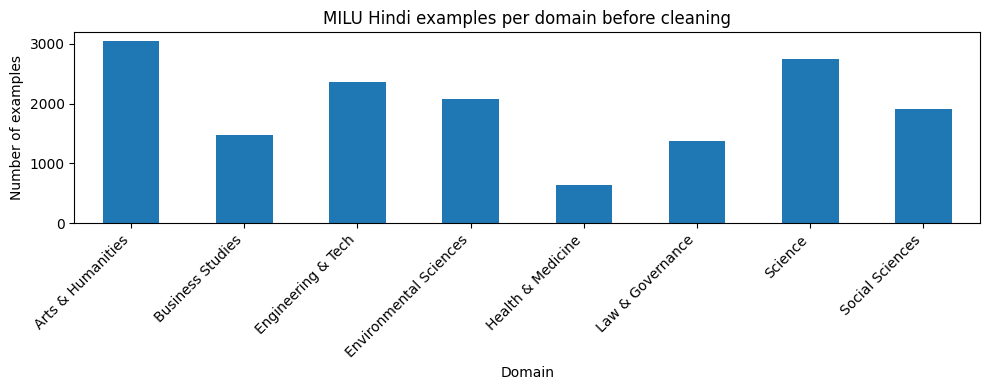

In [39]:
plt.figure(figsize=(10, 4))
df_raw["domain"].value_counts().sort_index().plot(kind="bar")
plt.title("MILU Hindi examples per domain before cleaning")
plt.xlabel("Domain")
plt.ylabel("Number of examples")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [40]:
df = df_raw.copy()

TEXT_COLUMNS = [
    "question",
    "option1",
    "option2",
    "option3",
    "option4",
    "target",
    "subject",
    "domain",
    "source_split",
]

for col in TEXT_COLUMNS:
    df[col] = df[col].fillna("").astype(str).str.strip()

df["target"] = df["target"].str.lower()
df["answer"] = df["target"].map(TARGET_TO_ANSWER)
df["is_translated"] = df["is_translated"].fillna(False).astype(bool)

print("Target distribution before filtering:")
display(df["target"].value_counts(dropna=False).to_frame("n_rows"))

print("Answer distribution before filtering:")
display(df["answer"].value_counts(dropna=False).to_frame("n_rows"))

Target distribution before filtering:


,n_rows
target,
option3,4064
option2,4042
option1,3939
option4,3598


Answer distribution before filtering:


,n_rows
answer,
C,4064
B,4042
A,3939
D,3598


In [41]:
SUBJECT_TO_REGIONALITY = {
    # regional
    "Arts and Culture": "regional",
    "Defense and Security": "regional",
    "Geography": "regional",
    "History": "regional",
    "Language Studies": "regional",
    "Law and Ethics": "regional",
    "Literature and Linguistics": "regional",
    "Politics and Governance": "regional",
    "Public Administration": "regional",
    "Religion and Spirituality": "regional",

    # regional implicit
    "Agriculture": "regional_implicit",
    "Anthropology": "regional_implicit",
    "Architecture and Design": "regional_implicit",
    "Business and Management": "regional_implicit",
    "Economics": "regional_implicit",
    "Education": "regional_implicit",
    "Energy and Power": "regional_implicit",
    "Environmental Science": "regional_implicit",
    "Ethics and Human Rights": "regional_implicit",
    "Finance and Investment": "regional_implicit",
    "Food Science": "regional_implicit",
    "Health and Medicine": "regional_implicit",
    "International Relations": "regional_implicit",
    "Media and Communication": "regional_implicit",
    "Music and Performing Arts": "regional_implicit",
    "Psychology": "regional_implicit",
    "Social Welfare and Development": "regional_implicit",
    "Sociology": "regional_implicit",
    "Sports and Recreation": "regional_implicit",
    "Technology and Innovation": "regional_implicit",
    "Transportation and Logistics": "regional_implicit",

    # region agnostic
    "Astronomy and Astrophysics": "region_agnostic",
    "Biology": "region_agnostic",
    "Chemistry": "region_agnostic",
    "Computer Science": "region_agnostic",
    "Earth Sciences": "region_agnostic",
    "Engineering": "region_agnostic",
    "Information Technology": "region_agnostic",
    "Logical Reasoning": "region_agnostic",
    "Materials Science": "region_agnostic",
    "Physics": "region_agnostic",
}

In [42]:
# Add regionality from manual subject mapping
df["regionality"] = df["subject"].map(SUBJECT_TO_REGIONALITY)
missing_regionality = sorted(df.loc[df["regionality"].isna(), "subject"].unique())
print("Missing regionality labels:", missing_regionality)
assert not missing_regionality

Missing regionality labels: []


In [43]:
subject_domain_regionality = (
    df[["subject", "domain", "regionality"]]
    .drop_duplicates()
    .sort_values(["regionality", "domain", "subject"])
    .reset_index(drop=True)
)
display(subject_domain_regionality)
print("Rows by regionality:")
display(df["regionality"].value_counts().sort_index().to_frame("n_rows"))
print("Rows by domain and regionality:")
display(
    pd.crosstab(
        df["domain"],
        df["regionality"],
        margins=True,
    )
)

,subject,domain,regionality
0,Engineering,Engineering & Tech,region_agnostic
1,Information Technology,Engineering & Tech,region_agnostic
2,Materials Science,Engineering & Tech,region_agnostic
3,Earth Sciences,Environmental Sciences,region_agnostic
4,Astronomy and Astrophysics,Science,region_agnostic
5,Biology,Science,region_agnostic
6,Chemistry,Science,region_agnostic
7,Computer Science,Science,region_agnostic
8,Logical Reasoning,Science,region_agnostic
9,Physics,Science,region_agnostic


Rows by regionality:


,n_rows
regionality,
region_agnostic,4460
regional,4130
regional_implicit,7053


Rows by domain and regionality:


regionality,region_agnostic,regional,regional_implicit,All
domain,,,,
Arts & Humanities,0,2226,815,3041
Business Studies,0,0,1482,1482
Engineering & Tech,1197,0,1171,2368
Environmental Sciences,519,518,1036,2073
Health & Medicine,0,0,638,638
Law & Governance,0,1267,113,1380
Science,2744,0,0,2744
Social Sciences,0,119,1798,1917
All,4460,4130,7053,15643


# Clean and dedup

In [44]:
# Clean invalid MCQ rows
n_before_cleaning = len(df)

df = df[
    (df["question"] != "")
    & (df["option1"] != "")
    & (df["option2"] != "")
    & (df["option3"] != "")
    & (df["option4"] != "")
    & (df["answer"].isin(VALID_ANSWERS))
].copy()

df = df.reset_index(drop=True)

n_after_cleaning = len(df)

print(f"Rows before basic MCQ cleaning: {n_before_cleaning}")
print(f"Rows after basic MCQ cleaning:  {n_after_cleaning}")
print(f"Removed invalid rows:           {n_before_cleaning - n_after_cleaning}")

print("\nRows by source split after cleaning:")
display(df["source_split"].value_counts().to_frame("n_rows"))

print("\nRows by domain after cleaning:")
display(df["domain"].value_counts().sort_index().to_frame("n_rows"))

print("\nRows by regionality after cleaning:")
display(df["regionality"].value_counts().sort_index().to_frame("n_rows"))

Rows before basic MCQ cleaning: 15643
Rows after basic MCQ cleaning:  15643
Removed invalid rows:           0

Rows by source split after cleaning:


,n_rows
source_split,
test,14831
validation,812



Rows by domain after cleaning:


,n_rows
domain,
Arts & Humanities,3041
Business Studies,1482
Engineering & Tech,2368
Environmental Sciences,2073
Health & Medicine,638
Law & Governance,1380
Science,2744
Social Sciences,1917



Rows by regionality after cleaning:


,n_rows
regionality,
region_agnostic,4460
regional,4130
regional_implicit,7053


In [45]:
# Check duplicates and conflicting duplicate answers before deduplication
DEDUP_COLUMNS = ["question", "option1", "option2", "option3", "option4"]

conflict_counts_raw = (
    df.groupby(DEDUP_COLUMNS)["answer"]
    .nunique()
    .reset_index(name="n_unique_answers")
)

conflicts_raw = conflict_counts_raw[conflict_counts_raw["n_unique_answers"] > 1]
print(f"Raw conflicting duplicate groups: {len(conflicts_raw)}")
display(conflicts_raw.head(20))

# Optional: inspect conflicting duplicates if any
if len(conflicts_raw) > 0:
    conflict_keys = conflicts_raw[DEDUP_COLUMNS]
    df_conflicts = df.merge(conflict_keys, on=DEDUP_COLUMNS, how="inner")
    df_conflicts = df_conflicts.sort_values(
        DEDUP_COLUMNS + ["source_split", "source_idx"]
    )
    display(df_conflicts.head(50))

Raw conflicting duplicate groups: 0


,question,option1,option2,option3,option4,n_unique_answers


In [46]:
# deduplicate
n_before_dedup = len(df)

df = df.drop_duplicates(subset=DEDUP_COLUMNS, keep="first").copy()
df = df.reset_index(drop=True)

n_after_dedup = len(df)

print(f"Rows before deduplication: {n_before_dedup}")
print(f"Rows after deduplication:  {n_after_dedup}")
print(f"Removed duplicates:        {n_before_dedup - n_after_dedup}")

remaining_duplicates = df.duplicated(subset=DEDUP_COLUMNS).sum()
print(f"Remaining duplicates by question/options: {remaining_duplicates}")

assert remaining_duplicates == 0

Rows before deduplication: 15643
Rows after deduplication:  15622
Removed duplicates:        21
Remaining duplicates by question/options: 0


In [47]:
# Final dataset statistics before saving
print("Final rows:", len(df))

print("\nRows by source split:")
display(df["source_split"].value_counts().to_frame("n_examples"))

print("\nRows by domain:")
display(df["domain"].value_counts().sort_index().to_frame("n_examples"))

print("\nRows by regionality:")
display(df["regionality"].value_counts().sort_index().to_frame("n_examples"))

print("\nRows by subject:")
display(df["subject"].value_counts().sort_index().to_frame("n_examples"))

print("\nRows by domain:")
display(df["domain"].value_counts().sort_index().to_frame("n_examples"))

print("\nDomain x regionality:")
display(pd.crosstab(df["domain"], df["regionality"], margins=True))

Final rows: 15622

Rows by source split:


,n_examples
source_split,
test,14830
validation,792



Rows by domain:


,n_examples
domain,
Arts & Humanities,3035
Business Studies,1482
Engineering & Tech,2368
Environmental Sciences,2073
Health & Medicine,635
Law & Governance,1372
Science,2743
Social Sciences,1914



Rows by regionality:


...

,n_examples
subject,
Agriculture,517
Anthropology,117
Architecture and Design,115
Arts and Culture,519
Astronomy and Astrophysics,147
Biology,519
Business and Management,447
Chemistry,519
Computer Science,520



Rows by domain:


,n_examples
domain,
Arts & Humanities,3035
Business Studies,1482
Engineering & Tech,2368
Environmental Sciences,2073
Health & Medicine,635
Law & Governance,1372
Science,2743
Social Sciences,1914



Domain x regionality:


regionality,region_agnostic,regional,regional_implicit,All
domain,,,,
Arts & Humanities,0,2225,810,3035
Business Studies,0,0,1482,1482
Engineering & Tech,1197,0,1171,2368
Environmental Sciences,519,518,1036,2073
Health & Medicine,0,0,635,635
Law & Governance,0,1264,108,1372
Science,2743,0,0,2743
Social Sciences,0,119,1795,1914
All,4459,4126,7037,15622


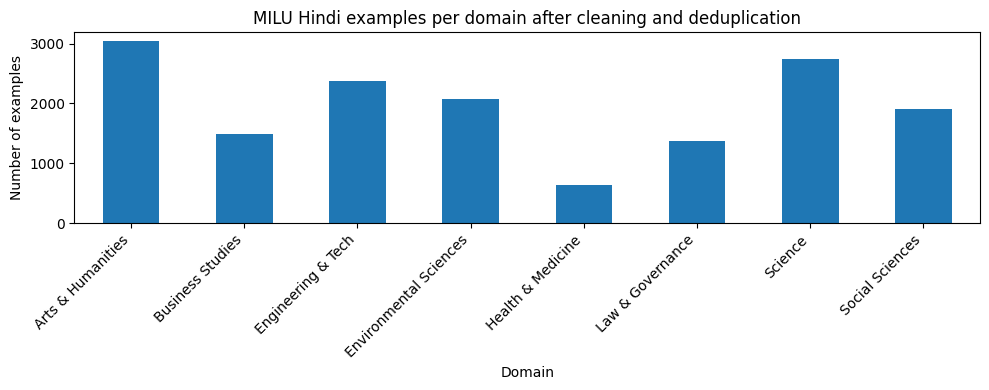

In [48]:
# Plots after cleaning and deduplication
plt.figure(figsize=(10, 4))
df["domain"].value_counts().sort_index().plot(kind="bar")
plt.title("MILU Hindi examples per domain after cleaning and deduplication")
plt.xlabel("Domain")
plt.ylabel("Number of examples")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

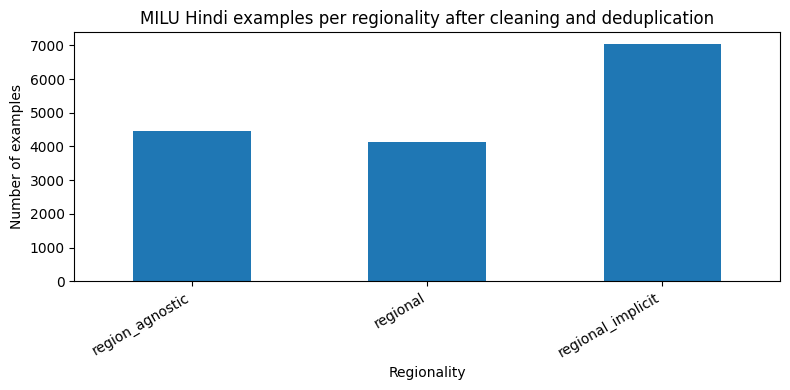

In [49]:
plt.figure(figsize=(8, 4))
df["regionality"].value_counts().sort_index().plot(kind="bar")
plt.title("MILU Hindi examples per regionality after cleaning and deduplication")
plt.xlabel("Regionality")
plt.ylabel("Number of examples")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [50]:
# Build SFT-format records
def make_prompt(row):
    return (
        f"{row['question']}\n\n"
        f"A) {row['option1']}\n"
        f"B) {row['option2']}\n"
        f"C) {row['option3']}\n"
        f"D) {row['option4']}"
    )


def safe_id_part(text):
    return (
        str(text)
        .strip()
        .replace("/", "_")
        .replace("\\", "_")
        .replace(" ", "_")
        .replace("-", "_")
        .replace(":", "_")
    )


def make_record(row, idx):
    source_split = safe_id_part(row["source_split"])
    source_idx = int(row["source_idx"])

    return {
        "id": f"milu_hindi_all_{idx:06d}_{source_split}_{source_idx}",
        "dataset": "milu",
        "language": "hindi",
        "split": "all",
        "task_type": "mcq",
        "prompt": make_prompt(row),
        "answer": row["answer"],
        "metadata": {
            "subject": row["subject"],
            "domain": row["domain"],
            "regionality": row["regionality"],
            "is_translated": bool(row["is_translated"]),
            "source_split": row["source_split"],
            "source_idx": source_idx,
        },
    }


records = []
for idx, row in df.reset_index(drop=True).iterrows():
    records.append(make_record(row, idx))
print(f"Created records: {len(records)}")
records[0]

Created records: 15622


{'id': 'milu_hindi_all_000000_test_0',
 'dataset': 'milu',
 'language': 'hindi',
 'split': 'all',
 'task_type': 'mcq',
 'prompt': 'निम्नलिखित में से शुद्ध वर्तनी वाला शब्द है\n\nA) कवयत्री\nB) घनिष्ठ\nC) चीन्ह\nD) ईर्षा',
 'answer': 'B',
 'metadata': {'subject': 'Language Studies',
  'domain': 'Arts & Humanities',
  'regionality': 'regional',
  'is_translated': False,
  'source_split': 'test',
  'source_idx': 0}}

In [51]:
# Validate records
VALID_DOMAINS = {
    "Arts & Humanities",
    "Business Studies",
    "Engineering & Tech",
    "Environmental Sciences",
    "Health & Medicine",
    "Law & Governance",
    "Science",
    "Social Sciences",
}

VALID_REGIONALITIES = {
    "regional",
    "regional_implicit",
    "region_agnostic",
}


def validate_record(record):
    expected_keys = {
        "id",
        "dataset",
        "language",
        "split",
        "task_type",
        "prompt",
        "answer",
        "metadata",
    }

    assert set(record.keys()) == expected_keys

    assert isinstance(record["id"], str)
    assert record["id"].startswith("milu_hindi_all_")
    assert record["dataset"] == "milu"
    assert record["language"] == "hindi"
    assert record["split"] == "all"
    assert record["task_type"] == "mcq"
    assert record["answer"] in {"A", "B", "C", "D"}

    prompt = record["prompt"]
    assert isinstance(prompt, str)
    assert prompt.strip()
    assert "\n\nA) " in prompt
    assert "\nB) " in prompt
    assert "\nC) " in prompt
    assert "\nD) " in prompt

    metadata = record["metadata"]

    assert set(metadata.keys()) == {
        "subject",
        "domain",
        "regionality",
        "is_translated",
        "source_split",
        "source_idx",
    }

    assert metadata["domain"] in VALID_DOMAINS
    assert metadata["regionality"] in VALID_REGIONALITIES
    assert isinstance(metadata["is_translated"], bool)
    assert metadata["source_split"] in {"test", "validation"}
    assert isinstance(metadata["source_idx"], int)


for record in records:
    validate_record(record)

print("All records validated successfully.")

All records validated successfully.


In [52]:
# Check unique ids
ids = [record["id"] for record in records]

print(f"Number of ids:        {len(ids)}")
print(f"Number of unique ids: {len(set(ids))}")

assert len(ids) == len(set(ids)), "Duplicate record ids found."

Number of ids:        15622
Number of unique ids: 15622


# Save

In [53]:
def make_record(row, idx):
    source_split = safe_id_part(row["source_split"])
    source_idx = int(row["source_idx"])

    return {
        "id": f"milu_hindi_all_{idx:06d}_{source_split}_{source_idx}",
        "dataset": "milu",
        "language": "hindi",
        "split": "all",
        "task_type": "mcq",
        "prompt": make_prompt(row),
        "answer": row["answer"],
        "metadata": {
            "subject": row["subject"],
            "domain": row["domain"],
            "regionality": row["regionality"],
            "is_translated": bool(row["is_translated"]),
            "source_split": row["source_split"],
            "source_idx": source_idx,
        },
    }

In [54]:
# Save all/train/val JSONL files
ALL_PATH = OUTPUT_DIR / "milu_hindi_all.jsonl"
TRAIN_PATH = OUTPUT_DIR / "milu_hindi_train.jsonl"
VAL_PATH = OUTPUT_DIR / "milu_hindi_val.jsonl"


def write_jsonl(records, path):
    with path.open("w", encoding="utf-8") as f:
        for record in records:
            f.write(json.dumps(record, ensure_ascii=False) + "\n")


def read_jsonl(path):
    loaded = []

    with path.open("r", encoding="utf-8") as f:
        for line in f:
            loaded.append(json.loads(line))

    return loaded


all_records = records
train_records = [
    record for record in records
    if record["metadata"]["source_split"] == "test"
]
val_records = [
    record for record in records
    if record["metadata"]["source_split"] == "validation"
]

print(f"All records:   {len(all_records)}")
print(f"Train records: {len(train_records)}")
print(f"Val records:   {len(val_records)}")
write_jsonl(all_records, ALL_PATH)
write_jsonl(train_records, TRAIN_PATH)
write_jsonl(val_records, VAL_PATH)
print(f"\nSaved all records to:   {ALL_PATH}")
print(f"Saved train records to: {TRAIN_PATH}")
print(f"Saved val records to:   {VAL_PATH}")

All records:   15622
Train records: 14830
Val records:   792

Saved all records to:   /scratch/workspace/emma/standard-project-m2-mystery-machine/multilingual/data/processed/milu/milu_hindi_all.jsonl
Saved train records to: /scratch/workspace/emma/standard-project-m2-mystery-machine/multilingual/data/processed/milu/milu_hindi_train.jsonl
Saved val records to:   /scratch/workspace/emma/standard-project-m2-mystery-machine/multilingual/data/processed/milu/milu_hindi_val.jsonl


In [55]:
# Save MILU subsets by regionality

REGIONALITY_TO_PATH_ALL = {
    "regional": OUTPUT_DIR / "milu_hindi_regional.jsonl",
    "regional_implicit": OUTPUT_DIR / "milu_hindi_regional_implicit.jsonl",
    "region_agnostic": OUTPUT_DIR / "milu_hindi_region_agnostic.jsonl",
}

REGIONALITY_TO_PATH_TRAIN = {
    "regional": OUTPUT_DIR / "milu_hindi_train_regional.jsonl",
    "regional_implicit": OUTPUT_DIR / "milu_hindi_train_regional_implicit.jsonl",
    "region_agnostic": OUTPUT_DIR / "milu_hindi_train_region_agnostic.jsonl",
}

print("Saving full MILU subsets by regionality")
for regionality, path in REGIONALITY_TO_PATH_ALL.items():
    subset_records = [
        record for record in all_records
        if record["metadata"]["regionality"] == regionality
    ]

    write_jsonl(subset_records, path)
    print(f"Saved {len(subset_records)} records to:")
    print(path)


print("\nSaving train-pool MILU subsets by regionality")
for regionality, path in REGIONALITY_TO_PATH_TRAIN.items():
    subset_records = [
        record for record in train_records
        if record["metadata"]["regionality"] == regionality
    ]

    write_jsonl(subset_records, path)
    print(f"Saved {len(subset_records)} records to:")
    print(path)

Saving full MILU subsets by regionality
Saved 4126 records to:
/scratch/workspace/emma/standard-project-m2-mystery-machine/multilingual/data/processed/milu/milu_hindi_regional.jsonl
Saved 7037 records to:
/scratch/workspace/emma/standard-project-m2-mystery-machine/multilingual/data/processed/milu/milu_hindi_regional_implicit.jsonl
Saved 4459 records to:
/scratch/workspace/emma/standard-project-m2-mystery-machine/multilingual/data/processed/milu/milu_hindi_region_agnostic.jsonl

Saving train-pool MILU subsets by regionality
Saved 3931 records to:
/scratch/workspace/emma/standard-project-m2-mystery-machine/multilingual/data/processed/milu/milu_hindi_train_regional.jsonl
Saved 6639 records to:
/scratch/workspace/emma/standard-project-m2-mystery-machine/multilingual/data/processed/milu/milu_hindi_train_regional_implicit.jsonl
Saved 4260 records to:
/scratch/workspace/emma/standard-project-m2-mystery-machine/multilingual/data/processed/milu/milu_hindi_train_region_agnostic.jsonl


In [56]:
# Verify regionality-specific MILU files

for regionality, path in REGIONALITY_TO_PATH_ALL.items():
    loaded_subset = read_jsonl(path)
    expected = [
        record for record in all_records
        if record["metadata"]["regionality"] == regionality
    ]
    print(f"all / {regionality}: {len(loaded_subset)} loaded, {len(expected)} expected")
    assert len(loaded_subset) == len(expected)
    for record in loaded_subset:
        validate_record(record)
        assert record["metadata"]["regionality"] == regionality


for regionality, path in REGIONALITY_TO_PATH_TRAIN.items():
    loaded_subset = read_jsonl(path)
    expected = [
        record for record in train_records
        if record["metadata"]["regionality"] == regionality
    ]

    print(f"train / {regionality}: {len(loaded_subset)} loaded, {len(expected)} expected")
    assert len(loaded_subset) == len(expected)
    for record in loaded_subset:
        validate_record(record)
        assert record["metadata"]["regionality"] == regionality
        assert record["metadata"]["source_split"] == "test"


print("All regionality-specific MILU files are valid.")

all / regional: 4126 loaded, 4126 expected
all / regional_implicit: 7037 loaded, 7037 expected
all / region_agnostic: 4459 loaded, 4459 expected
train / regional: 3931 loaded, 3931 expected
train / regional_implicit: 6639 loaded, 6639 expected
train / region_agnostic: 4260 loaded, 4260 expected
All regionality-specific MILU files are valid.


In [57]:
# Reload and validate saved files
loaded_all = read_jsonl(ALL_PATH)
loaded_train = read_jsonl(TRAIN_PATH)
loaded_val = read_jsonl(VAL_PATH)

print(f"Reloaded all:   {len(loaded_all)}")
print(f"Reloaded train: {len(loaded_train)}")
print(f"Reloaded val:   {len(loaded_val)}")

assert len(loaded_all) == len(all_records)
assert len(loaded_train) == len(train_records)
assert len(loaded_val) == len(val_records)

for record in loaded_all:
    validate_record(record)

for record in loaded_train:
    validate_record(record)
    assert record["metadata"]["source_split"] == "test"

for record in loaded_val:
    validate_record(record)
    assert record["metadata"]["source_split"] == "validation"

print("All saved JSONL files are valid.")

Reloaded all:   15622
Reloaded train: 14830
Reloaded val:   792
All saved JSONL files are valid.


In [58]:
# Line-count verification
with ALL_PATH.open("r", encoding="utf-8") as f:
    n_all_lines = sum(1 for _ in f)

with TRAIN_PATH.open("r", encoding="utf-8") as f:
    n_train_lines = sum(1 for _ in f)

with VAL_PATH.open("r", encoding="utf-8") as f:
    n_val_lines = sum(1 for _ in f)

print(f"all lines:   {n_all_lines}")
print(f"train lines: {n_train_lines}")
print(f"val lines:   {n_val_lines}")

assert n_all_lines == len(all_records)
assert n_train_lines == len(train_records)
assert n_val_lines == len(val_records)

all lines:   15622
train lines: 14830
val lines:   792


In [59]:
# Final summary from saved data
loaded_df = pd.DataFrame(
    {
        "id": record["id"],
        "dataset": record["dataset"],
        "language": record["language"],
        "split": record["split"],
        "task_type": record["task_type"],
        "answer": record["answer"],
        "subject": record["metadata"]["subject"],
        "domain": record["metadata"]["domain"],
        "regionality": record["metadata"]["regionality"],
        "is_translated": record["metadata"]["is_translated"],
        "source_split": record["metadata"]["source_split"],
    }
    for record in loaded_all
)

print("Final summary")
print("-------------")
print(f"Raw loaded rows:       {len(df_raw)}")
print(f"After cleaning:        {n_after_cleaning}")
print(f"After deduplication:   {len(df)}")
print(f"Saved all records:     {len(loaded_all)}")
print(f"Saved train records:   {len(loaded_train)}")
print(f"Saved val records:     {len(loaded_val)}")
print(f"All output path:       {ALL_PATH}")
print(f"Train output path:     {TRAIN_PATH}")
print(f"Val output path:       {VAL_PATH}")

print("\nBy source split:")
display(loaded_df["source_split"].value_counts().to_frame("n_examples"))

print("\nBy domain:")
display(loaded_df["domain"].value_counts().sort_index().to_frame("n_examples"))

print("\nBy regionality:")
display(loaded_df["regionality"].value_counts().sort_index().to_frame("n_examples"))

print("\nBy is_translated:")
display(loaded_df["is_translated"].value_counts(dropna=False).to_frame("n_examples"))

print("\nBy subject:")
display(loaded_df["subject"].value_counts().sort_index().to_frame("n_examples"))

Final summary
-------------
Raw loaded rows:       15643
After cleaning:        15643
After deduplication:   15622
Saved all records:     15622
Saved train records:   14830
Saved val records:     792
All output path:       /scratch/workspace/emma/standard-project-m2-mystery-machine/multilingual/data/processed/milu/milu_hindi_all.jsonl
Train output path:     /scratch/workspace/emma/standard-project-m2-mystery-machine/multilingual/data/processed/milu/milu_hindi_train.jsonl
Val output path:       /scratch/workspace/emma/standard-project-m2-mystery-machine/multilingual/data/processed/milu/milu_hindi_val.jsonl

By source split:


,n_examples
source_split,
test,14830
validation,792



By domain:


,n_examples
domain,
Arts & Humanities,3035
Business Studies,1482
Engineering & Tech,2368
Environmental Sciences,2073
Health & Medicine,635
Law & Governance,1372
Science,2743
Social Sciences,1914



By regionality:


,n_examples
regionality,
region_agnostic,4459
regional,4126
regional_implicit,7037



By is_translated:


,n_examples
is_translated,
False,14715
True,907



By subject:


,n_examples
subject,
Agriculture,517
Anthropology,117
Architecture and Design,115
Arts and Culture,519
Astronomy and Astrophysics,147
Biology,519
Business and Management,447
Chemistry,519
Computer Science,520
